# 04 — Airport operations dashboard (Gold consumer)

This notebook is the **consumer** of the Gold layer: it answers the project question — *how busy is each European
airport, how are its runways used and how long do ground phases take, by day and by hour?* — from the four Gold
tables only, without any join or heavy computation (that is the purpose of Gold). The Gold tables are small:
they are read with Spark and converted to pandas for plotting.

Showcase airports: Toulouse-Blagnac (**LFBO**) and Stavanger (**ENZV**). All times are UTC.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))      # projet_opdi/src
import opdi_pipeline                                     # first: on the VM, findspark points to Spark 3.5 (/opt/spark)
from opdi_pipeline.config import load_settings
from opdi_pipeline.spark import get_spark

ENV = "prod"                     # "prod": full scope (~/opdi-data) | "dev": 10-day sample (~/opdi-data-dev)
settings = load_settings(ENV)
spark = get_spark(settings)
print(f"{ENV}: scope [{settings.start}, {settings.end}[ | data {settings.data_root} | Spark {spark.version}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/09 19:37:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


prod: scope [2026-06-01, 2026-07-29[ | data /home/ubuntu/opdi-data | Spark 3.5.0


## Is Gold ready?

Consumers only read Gold when the `_SUCCESS` marker exists: it is written by the publication step, only if every validation check passed.

In [2]:
marker = settings.gold_dir / "_SUCCESS"
assert marker.exists(), "Gold is not published: the last run did not pass its quality checks"
print(marker.read_text().strip())
status = spark.read.parquet(str(settings.gold_dir / "run_status")).toPandas()
status.sort_values("published_at_utc").tail(4)[["run_id", "table_name", "row_count", "size_mb", "published_at_utc"]]

Gold published on 2026-11-09T18:59:27.839892+00:00 (run prod-8-1)


,run_id,table_name,row_count,size_mb,published_at_utc
2,prod-8-1,arrival_reference,3046,0.02,2026-11-09T18:59:28.186638+00:00
3,prod-8-1,airport_arrival_hourly,381863,2.42,2026-11-09T18:59:28.245924+00:00
4,prod-8-1,airport_arrival_daily,41334,1.06,2026-11-09T18:59:28.292188+00:00
5,prod-8-1,holding_hotspots,20438,0.13,2026-11-09T18:59:28.331779+00:00


In [3]:
import matplotlib.pyplot as plt
import pandas as pd

g = settings.gold_dir
daily = spark.read.parquet(str(g / "airport_daily_ops")).toPandas()
hourly = spark.read.parquet(str(g / "airport_hourly_ops")).toPandas()
runways = spark.read.parquet(str(g / "runway_usage")).toPandas()
ground = spark.read.parquet(str(g / "airport_ground_times")).toPandas()
for name, df in [("daily", daily), ("hourly", hourly), ("runways", runways), ("ground", ground)]:
    print(f"{name:8s} {len(df):>8,} rows")
SHOWCASE = ["LFBO", "ENZV"]

daily      43,397 rows
hourly    474,130 rows
runways    23,500 rows
ground     43,397 rows


## 1. The busiest airports

,airport_icao,airport_name,movements,per_day
204,EHAM,Amsterdam Airport Schiphol,81101,1398.0
874,LTFM,İstanbul Airport,76762,1323.0
148,EGLL,London Heathrow Airport,76300,1316.0
466,LEMD,Adolfo Suárez Madrid–Barajas Airport,74460,1284.0
42,EDDF,Frankfurt Main Airport,74422,1283.0
451,LEBL,Josep Tarradellas Barcelona-El Prat Airport,70334,1213.0
576,LFPG,Charles de Gaulle International Airport,68857,1187.0
47,EDDM,Munich Airport,58229,1004.0
720,LIRF,Rome–Fiumicino Leonardo da Vinci International...,58196,1003.0
625,LGAV,Athens Eleftherios Venizelos International Air...,56072,967.0


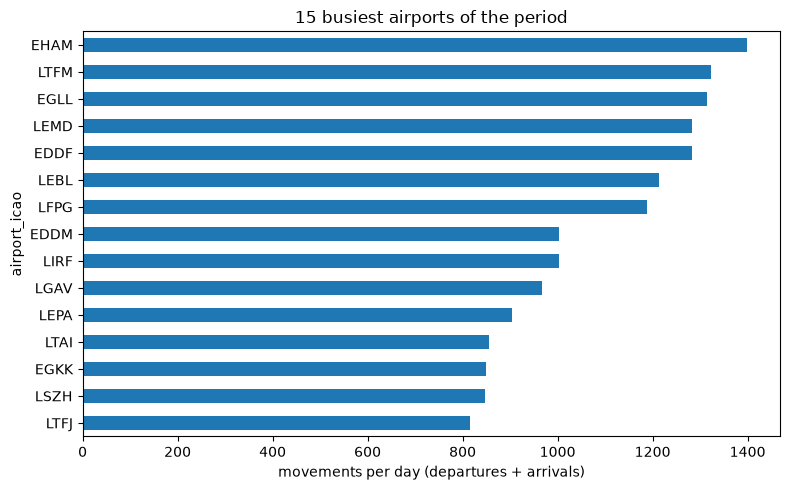

In [4]:
top = (daily.groupby(["airport_icao", "airport_name"], as_index=False)
             .agg(movements=("movements", "sum"), days=("movement_date", "nunique"))
             .assign(per_day=lambda d: d.movements / d.days)
             .nlargest(15, "per_day"))
ax = top.sort_values("per_day").plot.barh(x="airport_icao", y="per_day", legend=False, figsize=(8, 5))
ax.set_xlabel("movements per day (departures + arrivals)")
ax.set_title("15 busiest airports of the period")
plt.tight_layout()
top[["airport_icao", "airport_name", "movements", "per_day"]].round(0)

## 2. Daily traffic of the showcase airports

,movements_per_day,peak_hour,operators,pct_jet,pct_international,pct_precise_time
airport_icao,,,,,,
ENZV,148.6,21,10.0,53.1,46.0,10.6
LFBO,208.1,26,24.3,87.4,50.7,90.0


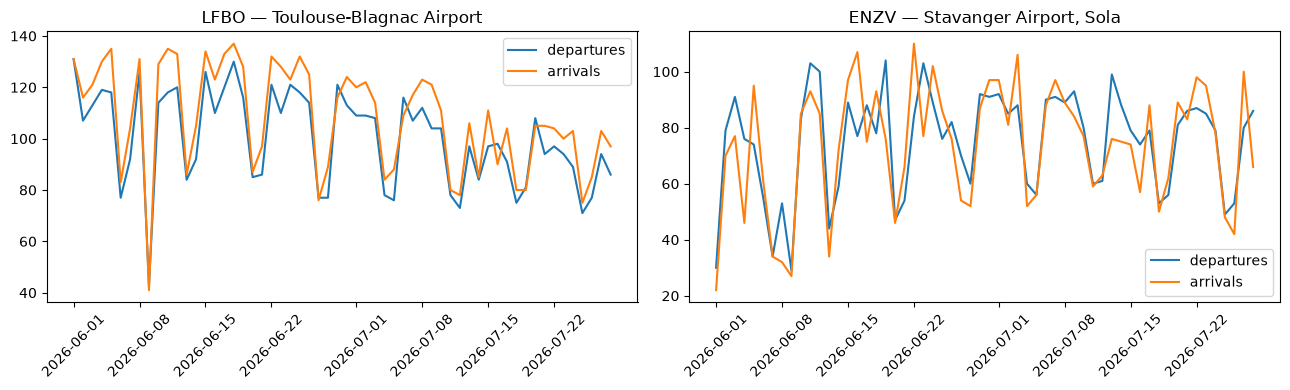

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, apt in zip(axes, SHOWCASE):
    d = daily[daily.airport_icao == apt].sort_values("movement_date")
    ax.plot(d.movement_date, d.departures, label="departures")
    ax.plot(d.movement_date, d.arrivals, label="arrivals")
    ax.set_title(f"{apt} — {d.airport_name.iloc[0] if len(d) else ''}")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
daily[daily.airport_icao.isin(SHOWCASE)].groupby("airport_icao").agg(
    movements_per_day=("movements", "mean"), peak_hour=("peak_hour_movements", "max"),
    operators=("distinct_operators", "mean"), pct_jet=("pct_jet", "mean"),
    pct_international=("pct_international", "mean"), pct_precise_time=("pct_time_from_event", "mean")).round(1)

## 3. Hourly profile (average movements per hour of the day, UTC)

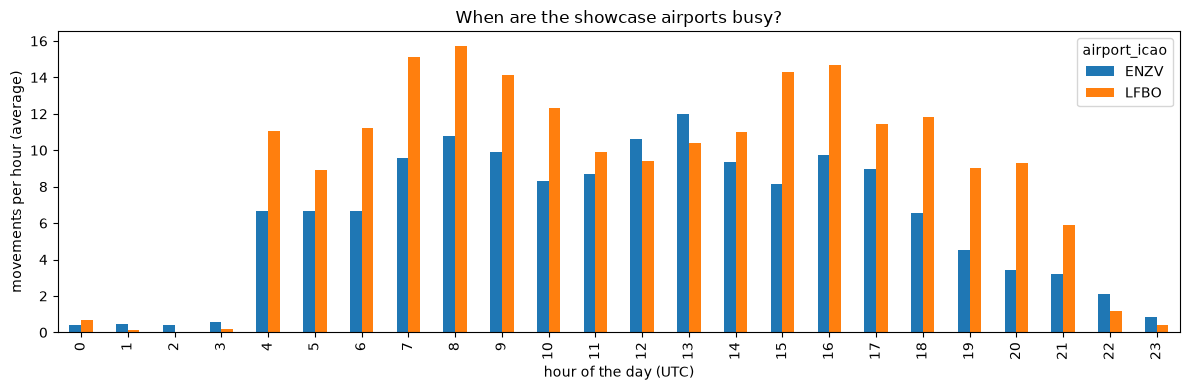

In [6]:
days = daily.groupby("airport_icao").movement_date.nunique()
profile = (hourly[hourly.airport_icao.isin(SHOWCASE)]
           .groupby(["airport_icao", "movement_hour"]).movements.sum().unstack(0).fillna(0)
           .div(days[SHOWCASE]).reindex(range(24), fill_value=0))
ax = profile.plot.bar(figsize=(12, 4))
ax.set_xlabel("hour of the day (UTC)")
ax.set_ylabel("movements per hour (average)")
ax.set_title("When are the showcase airports busy?")
plt.tight_layout()

## 4. Runway usage

,airport_icao,runway_ident,departures,arrivals,movements,length_ft,surface,share_pct
1,ENZV,18-36,253,382,635,9369.0,ASP,93.2
0,ENZV,10-28,8,38,46,8035.0,ASP,6.8
2,LFBO,14L-32R,4740,1732,6472,9843.0,ASP,60.6
3,LFBO,14R-32L,722,3490,4212,11483.0,ASP,39.4


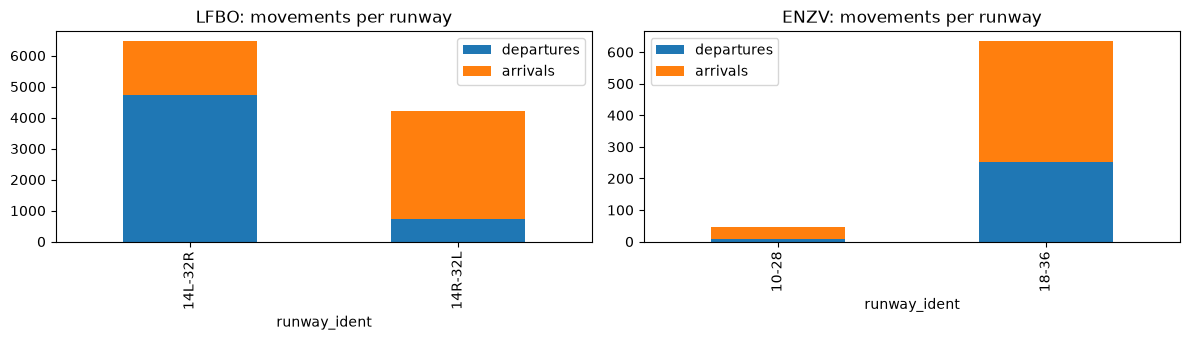

In [7]:
rw = (runways[runways.airport_icao.isin(SHOWCASE)]
      .groupby(["airport_icao", "runway_ident"], as_index=False)
      .agg(departures=("runway_departures", "sum"), arrivals=("runway_arrivals", "sum"),
           movements=("runway_movements", "sum"), length_ft=("length_ft", "first"), surface=("surface", "first")))
rw["share_pct"] = (rw.movements / rw.groupby("airport_icao").movements.transform("sum") * 100).round(1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, apt in zip(axes, SHOWCASE):
    r = rw[rw.airport_icao == apt].set_index("runway_ident")[["departures", "arrivals"]]
    if len(r):
        r.plot.bar(stacked=True, ax=ax, title=f"{apt}: movements per runway")
plt.tight_layout()
rw.sort_values(["airport_icao", "movements"], ascending=[True, False])

## 5. Taxi times (where parking positions are observed)

Taxi-out = parking → departure runway; taxi-in = arrival runway → parking. They only exist where the ground receivers see the aircraft at its parking position: the coverage says how representative a figure is, so the chart keeps airports with at least 100 measured departures.

,airport_icao,airport_name,measured_out,departures,measured_in,arrivals,median_taxi_out,median_taxi_in,coverage_out_pct,coverage_in_pct
823,LSZH,Zürich Airport,17497.0,24577.0,20252.0,24527.0,5.9,3.0,71.2,82.6
42,EDDF,Frankfurt Main Airport,9191.0,36654.0,11764.0,37768.0,5.8,4.3,25.1,31.1
51,EDDS,Stuttgart Airport,3804.0,8064.0,2942.0,8646.0,7.8,3.8,47.2,34.0
378,EYVI,Vilnius International Airport,1634.0,4065.0,1883.0,4095.0,6.8,3.6,40.2,46.0
746,LKPR,Václav Havel Airport Prague,1362.0,13617.0,2039.0,13849.0,7.9,2.4,10.0,14.7
45,EDDK,Cologne Bonn Airport,1166.0,11015.0,978.0,11534.0,8.9,4.8,10.6,8.5
929,UGTB,Tbilisi International Airport,855.0,4315.0,1999.0,4049.0,10.0,5.2,19.8,49.4
504,LFBO,Toulouse-Blagnac Airport,641.0,5806.0,711.0,6264.0,6.7,3.9,11.0,11.4
46,EDDL,Düsseldorf Airport,591.0,14924.0,1522.0,14797.0,6.8,2.7,4.0,10.3
221,EIDW,Dublin Airport,415.0,23154.0,508.0,23144.0,9.9,5.4,1.8,2.2


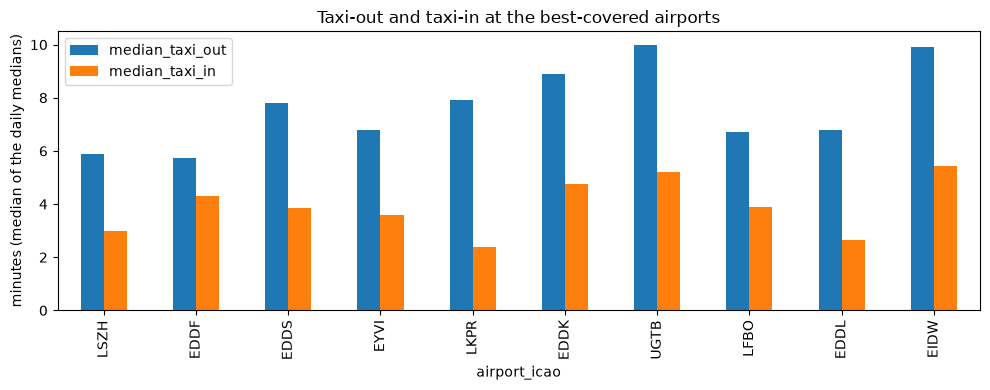

In [8]:
taxi = (ground.groupby(["airport_icao", "airport_name"], as_index=False)
              .agg(measured_out=("taxi_out_measured_flights", "sum"), departures=("total_departures", "sum"),
                   measured_in=("taxi_in_measured_flights", "sum"), arrivals=("total_arrivals", "sum"),
                   median_taxi_out=("median_taxi_out_min", "median"), median_taxi_in=("median_taxi_in_min", "median")))
taxi["coverage_out_pct"] = (taxi.measured_out / taxi.departures * 100).round(1)
taxi["coverage_in_pct"] = (taxi.measured_in / taxi.arrivals * 100).round(1)
best = taxi[taxi.measured_out >= 100].nlargest(10, "measured_out")
if len(best):
    ax = best.set_index("airport_icao")[["median_taxi_out", "median_taxi_in"]].plot.bar(figsize=(10, 4))
    ax.set_ylabel("minutes (median of the daily medians)")
    ax.set_title("Taxi-out and taxi-in at the best-covered airports")
    plt.tight_layout()
taxi.sort_values("measured_out", ascending=False).head(10).round(1)

## 6. Reading the figures

*Production run prod-8, June 1 – July 28, 2026 (58 days), times in UTC.*

- **Busiest airports.** Amsterdam (1,398 movements per day), Istanbul (1,323), London-Heathrow (1,316), Madrid
  (1,284) and Frankfurt (1,283) lead the period, followed by Barcelona and Paris-CDG (1,187). The ranking is plausible
  for a summer period.
- **Toulouse-Blagnac (LFBO).** 208 movements per day on average, up to 26 in the peak hour, 24 operators, 87 % jets
  and 51 % international flights. Weekdays are busier than weekends (about 230 movements per day against 160 on Saturdays and
  172 on Sundays); the busiest hours are 07–08 and 15–16 UTC. The two parallel runways are used in a segregated way: 14L/32R carries 61 % of the
  movements and mostly departures (4,740 departures, 1,732 arrivals), 14R/32L mostly arrivals (3,490 arrivals, 722
  departures). 90 % of the movement times come from runway / parking events.
- **Stavanger-Sola (ENZV).** 149 movements per day, up to 21 per hour, 10 operators, only 53 % jets (turboprops and
  offshore helicopter traffic) and 46 % international flights. Traffic drops at weekends. Runway 18/36 carries 93 % of
  the movements. Only 10.6 % of the movement times come from an airport event: the ground coverage of the ADS-B
  receivers is poor at Stavanger, so its hourly profile relies mostly on first / last seen times.
- **Taxi times.** They only exist where the receivers see the aircraft at its parking position. Zurich is the best
  covered airport (71 % of departures, 83 % of arrivals measured): median taxi-out 5.9 min, taxi-in 3.0 min.
  Frankfurt: 5.8 / 4.3 min with 25–31 % coverage. Toulouse (6.7 / 3.9 min) is measured for only 11 % of its flights,
  and airports below a few % (Dublin 2 %) are not representative.
- **Source gap.** The daily curves show the gap of June 9 (no data from 10:00 to 23:59 UTC in the source); the Gold
  regularity check flags these hours, and the arrival study (notebook 05) excludes them.